In [1]:
from wpp import cache, data, db
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
with db.get_con() as con:
    pois_dim = cache.cached_parquet(
        "pois",
        lambda: data.load_pois(con),
    )
    poi_visits = cache.cached_parquet(
        "static_poi_segregation",
        lambda: data.load_static_poi_segregation(con),
    ).with_columns(pl.col("TOTAL_VISITORS").cast(pl.Float64))
    poi_visits_weekly = cache.cached_parquet(
        "weekly_poi_segregation",
        lambda: data.load_weekly_poi_segregation(con),
    )

    cbg_visits = cache.cached_parquet(
        "static_cbg_segregation",
        lambda: data.load_static_cbg_segregation(con),
    )
    cbg_visits_weekly = cache.cached_parquet(
        "weekly_cbg_segregation",
        lambda: data.load_weekly_cbg_segregation(con),
    )

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [3]:
pois_weekly = pois_dim.join(poi_visits_weekly, on="ID_STORE")
pois_weekly.head()

CBSA_NAME,ID_STORE,POI_GEOID,CBSAFP,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,NAICS_TITLE,CBSA_NAME_FULL,DATE_RANGE_START,DATE_RANGE_END,AVG_TMEAN,AVG_TMIN,AVG_TMAX,NUM_TEMPERATURE_DAYS,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,AVG_DIST_1,AVG_DIST_2,AVG_DIST_3,AVG_DIST_4,NUM_HOME_GROUPS_1,NUM_HOME_GROUPS_2,NUM_HOME_GROUPS_3,NUM_HOME_GROUPS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION,AVG_DIST,NUM_HOME_GROUPS
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i32,"decimal[38,0]",str,str,str,datetime[μs],datetime[μs],f64,f64,f64,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64,f64,i64
"""Miami""","""10000007""","""120860176003""","""33100""","""Painting and Wall Covering Con…","""Painting and Wall Covering Con…","""8270 Sw 149Th Ct""","""Miami""","""FL""","""US""","""238320""","""Building Finishing Contractors""","""Painting and Wall Covering Con…",1970-01-01,2038-01-01,-80.434624,25.69067,"b""\x01\x01\x00\x00\x00Bd\xec\xdf\xd0\x1bT\xc0\x0dT\xc6\xbf\xcf\xb09@""",481139,32574,"""Other""","""Painting and Wall Covering Con…","""Miami-Fort Lauderdale-West Pal…",2025-01-13 00:00:00,2025-01-19 00:00:00,20.15737,15.731842,24.582899,7,237,60,60,null,8268.419225,11498.412621,23232.174225,null,5,2,2,0,357,0.663866,0.168067,0.168067,null,0.385154,11326.192065,9
"""Miami""","""10000007""","""120860176003""","""33100""","""Painting and Wall Covering Con…","""Painting and Wall Covering Con…","""8270 Sw 149Th Ct""","""Miami""","""FL""","""US""","""238320""","""Building Finishing Contractors""","""Painting and Wall Covering Con…",1970-01-01,2038-01-01,-80.434624,25.69067,"b""\x01\x01\x00\x00\x00Bd\xec\xdf\xd0\x1bT\xc0\x0dT\xc6\xbf\xcf\xb09@""",481139,32574,"""Other""","""Painting and Wall Covering Con…","""Miami-Fort Lauderdale-West Pal…",2025-01-20 00:00:00,2025-01-26 00:00:00,15.367071,10.933757,19.800385,7,162,27,54,27,7653.992466,1310.343713,2091.296876,1223.918489,2,1,2,1,270,0.6,0.1,0.2,0.1,0.466667,5264.081075,6
"""Miami""","""10000007""","""120860176003""","""33100""","""Painting and Wall Covering Con…","""Painting and Wall Covering Con…","""8270 Sw 149Th Ct""","""Miami""","""FL""","""US""","""238320""","""Building Finishing Contractors""","""Painting and Wall Covering Con…",1970-01-01,2038-01-01,-80.434624,25.69067,"b""\x01\x01\x00\x00\x00Bd\xec\xdf\xd0\x1bT\xc0\x0dT\xc6\xbf\xcf\xb09@""",481139,32574,"""Other""","""Painting and Wall Covering Con…","""Miami-Fort Lauderdale-West Pal…",2025-01-27 00:00:00,2025-02-02 00:00:00,20.627464,14.678457,26.576471,7,74,223,null,null,643.647107,25372.993447,null,null,1,4,0,0,297,0.249158,0.750842,null,null,0.334456,19211.47281,5
"""Miami""","""10000007""","""120860176003""","""33100""","""Painting and Wall Covering Con…","""Painting and Wall Covering Con…","""8270 Sw 149Th Ct""","""Miami""","""FL""","""US""","""238320""","""Building Finishing Contractors""","""Painting and Wall Covering Con…",1970-01-01,2038-01-01,-80.434624,25.69067,"b""\x01\x01\x00\x00\x00Bd\xec\xdf\xd0\x1bT\xc0\x0dT\xc6\xbf\xcf\xb09@""",481139,32574,"""Other""","""Painting and Wall Covering Con…","""Miami-Fort Lauderdale-West Pal…",2025-02-03 00:00:00,2025-02-09 00:00:00,22.743014,17.531885,27.954142,7,25,50,127,26,28533.061074,8579.943389,386.246967,1675.632207,1,2,2,1,228,0.109649,0.219298,0.557018,0.114035,0.409357,5416.418853,6
"""Miami""","""10000007""","""120860176003""","""33100""","""Painting and Wall Covering Con…","""Painting and Wall Covering Con…","""8270 Sw 149Th Ct""","""Miami""","""FL""","""US""","""238320""","""Building Finishing Contractors""","""Painting and Wall Covering Con…",1970-01-01,2038-01-01,-80.434624,25.69067,"b""\x01\x01\x00\x00\x00Bd\xec\xdf\xd0\x1bT\xc0\x0dT\xc6\xbf\xcf\xb09@""",481139,32574,"""Other""","""Painting a

In [4]:
def plot(agg, label, axes):
    plots = [
        ("NUM_POIS", "POIs"),
        ("TOTAL_VISITORS", "Total visitors"),
        ("MEDIAN_VISITORS", "Median visitors"),
        ("MEAN_DIST", "Mean distance"),
        ("MEAN_SEGREGATION", "Mean segregation"),
        ("W_MEAN_SEGREGATION", "Weighted mean segregation"),
        ("MEAN_NUM_HOME_GROUPS", "Mean distinct homes"),
        ("MEDIAN_NUM_HOME_GROUPS", "Median distinct homes", ("Q25_NUM_HOME_GROUPS", "Q75_NUM_HOME_GROUPS")),
    ]

    flat = axes.flatten()
    for ax, plot in zip(flat, plots):
        assert len(plot) in (2, 3)
        column, title, *rest = plot
        err = rest[0] if rest else None

        x = agg["DATE_RANGE_START"]
        ax.plot(
            x,
            agg[column],
            label=label
        )
        ax.set_title(title)
        ax.grid(alpha=0.15)

        # if err:
        #     ax.fill_between(x, agg[err[0]], agg[err[1]], color="C0", alpha=0.2, linewidth=0)

    for ax in list(axes.flat)[len(plots):]:
        ax.set_visible(False)
        
    sns.despine(fig=fig)

In [9]:
filter_expressions = [
    ("All", pl.lit(True)),
    (r"#HOMES $\geq 10$", pl.col("NUM_HOME_GROUPS") >= 10),
    (r"VISITORS $\geq 1000$", pl.col("TOTAL_VISITORS") >= 1000),
    (r"#HOMES $\geq 10$ & VISITORS $\geq 1000$", (pl.col("NUM_HOME_GROUPS") >= 10, pl.col("TOTAL_VISITORS") >= 1000)),
    (r"$\sum_{poi}$#HOMES $\geq 10 \cdot 52$", pl.col("NUM_HOME_GROUPS").sum().over("ID_STORE") >= 10 * 52),
    (r"$\sum_{poi}$#HOMES $\geq 40 \cdot 52$", pl.col("NUM_HOME_GROUPS").sum().over("ID_STORE") >= 100 * 52),
]

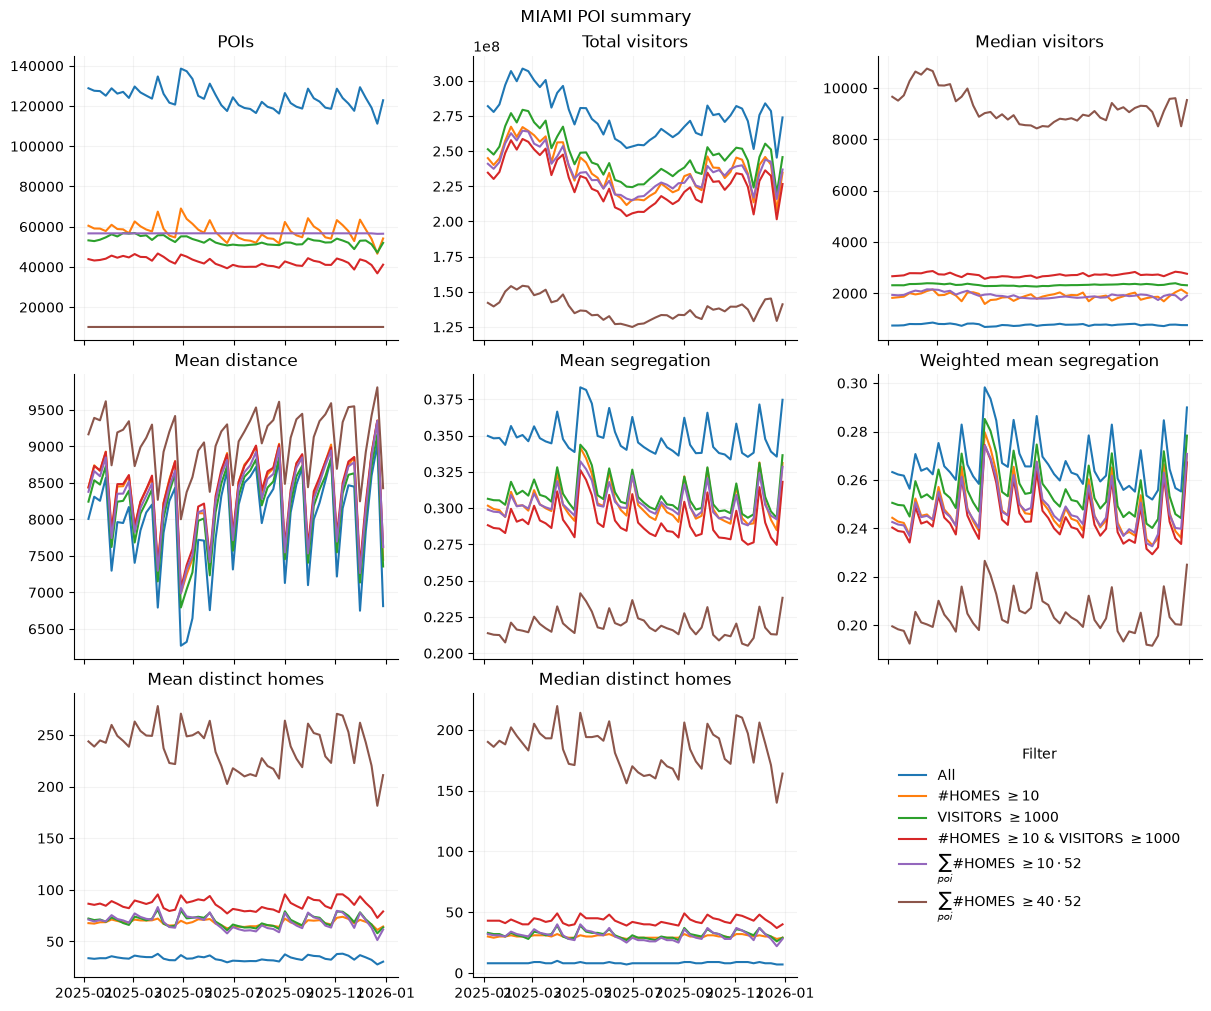

In [10]:
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True,
)

for label, f in filter_expressions:
    agg = (
        pois_weekly.filter(f)
        .group_by("DATE_RANGE_START")
        .agg(
            pl.col("ID_STORE").n_unique().alias("NUM_POIS"),
            pl.col("TOTAL_VISITORS").sum().alias("TOTAL_VISITORS"),
            pl.col("TOTAL_VISITORS").median().alias("MEDIAN_VISITORS"),
            pl.col("AVG_DIST").mean().alias("MEAN_DIST"),
            pl.col("SEGREGATION").mean().alias("MEAN_SEGREGATION"),
            ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_MEAN_SEGREGATION"),
            pl.col("NUM_HOME_GROUPS").mean().alias("MEAN_NUM_HOME_GROUPS"),
            pl.col("NUM_HOME_GROUPS").median().alias("MEDIAN_NUM_HOME_GROUPS"),
            pl.col("NUM_HOME_GROUPS").quantile(.25).alias("Q25_NUM_HOME_GROUPS"),
            pl.col("NUM_HOME_GROUPS").quantile(.75).alias("Q75_NUM_HOME_GROUPS"),
        )
        .sort("DATE_RANGE_START")
    )
    plot(agg, label, axes)

# Legend in the next free axis
n_plots = 8
free_ax = axes.flat[n_plots]
free_ax.set_visible(True)
free_ax.axis("off")

handles, labels = axes.flat[0].get_legend_handles_labels()
free_ax.legend(handles, labels, loc="center", title="Filter", frameon=False)
fig.suptitle("MIAMI POI summary")
fig.savefig("pois.png", dpi=200)

In [7]:
def plot_cbgs(agg, label, axes):
    plots = [
        ("NUM_CBGS", "Census block groups"),
        ("TOTAL_VISITORS", "Total visitors"),
        ("MEDIAN_VISITORS", "Median visitors"),
        ("MEAN_DIST", "Mean distance"),
        ("MEAN_SEGREGATION", "Mean segregation"),
        ("W_MEAN_SEGREGATION", "Weighted mean segregation"),
        ("MEAN_NUM_POIS", "Mean pois visited"),
        ("MEDIAN_NUM_POIS", "Median pois visited", ("Q25_NUM_POIS", "Q75_NUM_POIS")),
    ]

    flat = axes.flatten()
    for ax, plot in zip(flat, plots):
        assert len(plot) in (2, 3)
        column, title, *rest = plot
        err = rest[0] if rest else None

        x = agg["DATE_RANGE_START"]
        ax.plot(
            x,
            agg[column],
            label=label
        )
        ax.set_title(title)
        ax.grid(alpha=0.15)

        # if err:
        #     ax.fill_between(x, agg[err[0]], agg[err[1]], color="C0", alpha=0.2, linewidth=0)

    for ax in list(axes.flat)[len(plots):]:
        ax.set_visible(False)
        
    sns.despine(fig=fig)

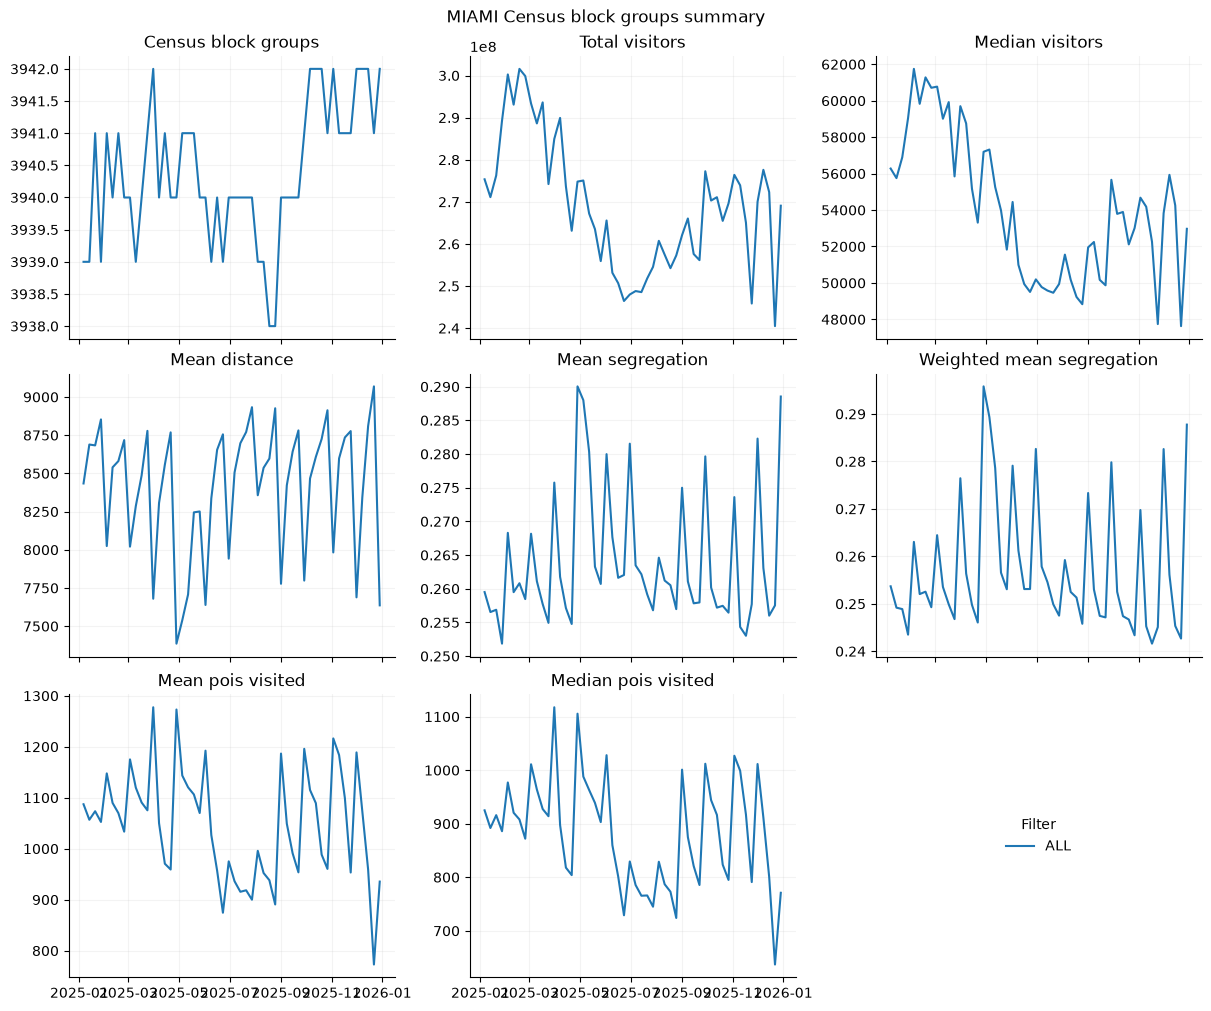

In [8]:
agg = (
    cbg_visits_weekly
    .group_by("DATE_RANGE_START")
    .agg(
        pl.col("GEOID").n_unique().alias("NUM_CBGS"),
        pl.col("TOTAL_VISITORS").sum().alias("TOTAL_VISITORS"),
        pl.col("TOTAL_VISITORS").median().alias("MEDIAN_VISITORS"),
        pl.col("AVG_DIST").mean().alias("MEAN_DIST"),
        pl.col("SEGREGATION").mean().alias("MEAN_SEGREGATION"),
        ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_MEAN_SEGREGATION"),
        pl.col("NUM_POIS").mean().alias("MEAN_NUM_POIS"),
        pl.col("NUM_POIS").median().alias("MEDIAN_NUM_POIS"),
        pl.col("NUM_POIS").quantile(.25).alias("Q25_NUM_POIS"),
        pl.col("NUM_POIS").quantile(.75).alias("Q75_NUM_POIS"),
    )
    .sort("DATE_RANGE_START")
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True,
)
plot_cbgs(agg, "ALL", axes)

# Legend in the next free axis
n_plots = 8
free_ax = axes.flat[n_plots]
free_ax.set_visible(True)
free_ax.axis("off")

handles, labels = axes.flat[0].get_legend_handles_labels()
free_ax.legend(handles, labels, loc="center", title="Filter", frameon=False)
fig.suptitle("MIAMI Census block groups summary")
fig.savefig("cbgs.png", dpi=200)